In [3]:
# IMPORTAR LIBRERIAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn: libreria de Machine Learning
from sklearn.model_selection import train_test_split     # Para dividir los datos
from sklearn.dummy import DummyClassifier                 # Para el baseline
from sklearn.linear_model import LogisticRegression       # Modelo de clasificacion
from sklearn.preprocessing import StandardScaler          # Normalizacion
from sklearn.pipeline import Pipeline                     # Une normalizacion + modelo
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Configurar semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configurar estilo de matplotlib
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerias importadas")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")
print(f"Scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerias importadas
Pandas version: 2.2.3
Numpy version: 2.4.6
Scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [4]:
# 5.1 VARIABLE OBJETIVO
print("5.1 VARIABLE OBJETIVO")
print("=" * 60)
print("Nombre:        requiere_capacitacion")
print("Tipo:          Clasificacion (binaria)")
print("Descripcion:   Predecir si un colaborador necesita capacitacion")
print("Valores:       0 = No requiere | 1 = Si requiere")
print("Justificacion: Ayuda a RRHH a decidir a quien capacitar primero,")
print("               antes de que baje su desempeño")

5.1 VARIABLE OBJETIVO
Nombre:        requiere_capacitacion
Tipo:          Clasificacion (binaria)
Descripcion:   Predecir si un colaborador necesita capacitacion
Valores:       0 = No requiere | 1 = Si requiere
Justificacion: Ayuda a RRHH a decidir a quien capacitar primero,
               antes de que baje su desempeño


In [5]:
# GENERAR DATASET SINTETICO DE 600 COLABORADORES - HRTECH PEOPLE ANALYTICS
# El dataset limpio solo tiene 10 colaboradores, con eso no se puede dividir 70/15/15.
# Por eso generamos 600 colaboradores con las mismas columnas y rangos del dataset real.
n = 600

df_g8 = pd.DataFrame({"id_empleado": range(1, n + 1)})
df_g8["departamento"] = np.random.choice(["IT", "RRHH", "Finanzas", "Marketing", "Ventas"], n)
df_g8["edad"] = np.random.randint(21, 56, n)                                   # 21 a 55 años
df_g8["desempeño"] = np.random.normal(80, 9, n).clip(50, 100).round(0)         # 0 a 100
df_g8["salario"] = np.random.choice([550, 600, 650, 700, 750, 800, 900, 950], n)
df_g8["tiempo_empresa_anios"] = np.random.randint(0, 11, n)                    # 0 a 10 años
df_g8["horas_capacitacion"] = np.random.choice([6, 8, 10, 12], n)
df_g8["satisfaccion"] = np.random.randint(1, 6, n)                             # 1 a 5
df_g8["horas_extra"] = np.random.randint(0, 16, n)
df_g8["curso_aprobado"] = np.random.binomial(1, 0.75, n)                       # 75% aprueba su curso

# Puntaje de riesgo: menor desempeño, menor satisfaccion, menos horas de capacitacion,
# mas horas extra y no aprobar el curso => mayor necesidad de capacitacion
# CORRECCIÓN: Se cambió 'df' por 'df_g8' para que haga referencia al DataFrame con todos los datos sintéticos.
riesgo = (
    - 0.10 * (df_g8["desempeño"] - 80)
    - 0.45 * (df_g8["satisfaccion"] - 3)
    - 0.15 * (df_g8["horas_capacitacion"] - 9)
    + 0.06 * (df_g8["horas_extra"] - 7)
    - 0.60 * df_g8["curso_aprobado"]
    + np.random.normal(0, 0.8, n)                                            # Ruido aleatorio
)
probabilidad = 1 / (1 + np.exp(-riesgo))
df_g8["requiere_capacitacion"] = np.random.binomial(1, probabilidad)

print(f"Dataset HRTech creado: {df_g8.shape[0]} colaboradores, {df_g8.shape[1]} columnas")
print(f"\nPrimeras 5 filas:")
print(df_g8.head().to_string())

Dataset HRTech creado: 600 colaboradores, 11 columnas

Primeras 5 filas:
   id_empleado departamento  edad  desempeño  salario  tiempo_empresa_anios  horas_capacitacion  satisfaccion  horas_extra  curso_aprobado  requiere_capacitacion
0            1    Marketing    31       84.0      950                     2                  10             2            1               1                      1
1            2       Ventas    55       78.0      700                    10                   8             4           12               1                      0
2            3     Finanzas    39       90.0      550                     7                  10             1           12               1                      0
3            4       Ventas    40       79.0      900                     9                  10             3            5               1                      0
4            5       Ventas    38       76.0      750                     7                   6             2        

In [6]:
# VERIFICACIÓN DE CIRCULARIDAD
auc_techo = roc_auc_score(df_g8['requiere_capacitacion'], probabilidad)
print(f'ROC-AUC máximo alcanzable con la probabilidad verdadera: {auc_techo:.3f}')
print('Cualquier modelo entrenado sobre estos datos queda limitado por ese techo (el ruido es parte del diseño).')
print('Conclusión: las métricas de la sección 5.5 describen el ajuste a datos simulados, NO el desempeño en producción.')

ROC-AUC máximo alcanzable con la probabilidad verdadera: 0.816
Cualquier modelo entrenado sobre estos datos queda limitado por ese techo (el ruido es parte del diseño).
Conclusión: las métricas de la sección 5.5 describen el ajuste a datos simulados, NO el desempeño en producción.


In [7]:
# 2. VERIFICAR CALIDAD DEL DATASET
print("INFORMACIÓN DEL DATASET MODELADO (df_g8):")
print("=" * 50)
df_g8.info()

print("\nVALORES NULOS POR COLUMNA:")
print(df_g8.isnull().sum())

print(f"\nDuplicados: {df_g8.duplicated().sum()}")

print("\nDISTRIBUCION DE requiere_capacitacion (5.2.2):")
print(df_g8["requiere_capacitacion"].value_counts())
print((df_g8["requiere_capacitacion"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

INFORMACIÓN DEL DATASET MODELADO (df_g8):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_empleado            600 non-null    int64  
 1   departamento           600 non-null    object 
 2   edad                   600 non-null    int64  
 3   desempeño              600 non-null    float64
 4   salario                600 non-null    int64  
 5   tiempo_empresa_anios   600 non-null    int64  
 6   horas_capacitacion     600 non-null    int64  
 7   satisfaccion           600 non-null    int64  
 8   horas_extra            600 non-null    int64  
 9   curso_aprobado         600 non-null    int64  
 10  requiere_capacitacion  600 non-null    int64  
dtypes: float64(1), int64(9), object(1)
memory usage: 51.7+ KB

VALORES NULOS POR COLUMNA:
id_empleado              0
departamento             0
edad                     0
desem

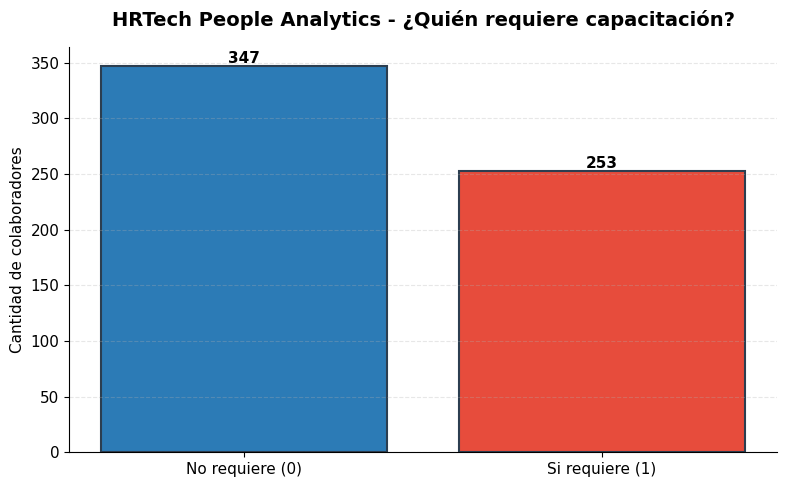

In [8]:
# GRÁFICO 1: Distribucion de la variable objetivo
conteo = df_g8["requiere_capacitacion"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(["No requiere (0)", "Si requiere (1)"], conteo.values,
                color=['#2c7bb6', '#e74c3c'], edgecolor='#2c3e50', linewidth=1.5)

for barra, valor in zip(barras, conteo.values):
    ax.text(barra.get_x() + barra.get_width()/2., barra.get_height(),
            f'{valor}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('HRTech People Analytics - ¿Quién requiere capacitación?', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Cantidad de colaboradores', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.show()

FACTORES PROMEDIO SEGÚN LA NECESIDAD DE CAPACITACIÓN:
                       desempeño  satisfaccion  horas_capacitacion  horas_extra
requiere_capacitacion                                                          
0                          82.33          3.19                9.24         7.61
1                          76.28          2.50                8.66         8.76


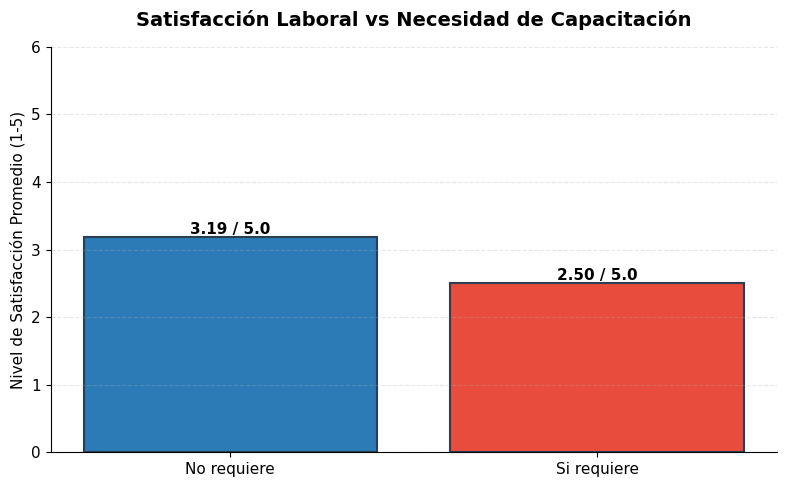


HALLAZGOS (calculados sobre df_g8, no escritos a mano):
   • desempeño: 76.28 en quienes requieren capacitación vs 82.33 en quienes no (menor en quienes requieren)
   • satisfaccion: 2.50 en quienes requieren capacitación vs 3.19 en quienes no (menor en quienes requieren)
   • horas_capacitacion: 8.66 en quienes requieren capacitación vs 9.24 en quienes no (menor en quienes requieren)
   • horas_extra: 8.76 en quienes requieren capacitación vs 7.61 en quienes no (mayor en quienes requieren)


In [9]:
# COMPARAR FACTORES ENTRE LOS QUE REQUIEREN Y NO REQUIEREN CAPACITACIÓN
promedios = df_g8.groupby("requiere_capacitacion")[["desempeño", "satisfaccion", "horas_capacitacion", "horas_extra"]].mean()

print("FACTORES PROMEDIO SEGÚN LA NECESIDAD DE CAPACITACIÓN:")
print("=" * 50)
print(promedios.round(2).to_string())

# Gráfico comparativo de la satisfacción
fig, ax = plt.subplots(figsize=(8, 5))
categorias = ['No requiere', 'Si requiere']
valores = [promedios.loc[0, 'satisfaccion'], promedios.loc[1, 'satisfaccion']]
barras = ax.bar(categorias, valores, color=['#2c7bb6', '#e74c3c'], edgecolor='#2c3e50', linewidth=1.5)

for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width()/2., barra.get_height(),
            f'{valor:.2f} / 5.0', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Satisfacción Laboral vs Necesidad de Capacitación', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Nivel de Satisfacción Promedio (1-5)', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')
ax.set_ylim(0, 6)

plt.tight_layout()
plt.show()

print("\nHALLAZGOS (calculados sobre df_g8, no escritos a mano):")
for var in promedios.columns:
    si, no = promedios.loc[1, var], promedios.loc[0, var]
    sentido = "mayor" if si > no else "menor"
    print(f"   • {var}: {si:.2f} en quienes requieren capacitación vs {no:.2f} en quienes no ({sentido} en quienes requieren)")

In [10]:
# 5.2.1 DEFINIR VARIABLES PREDICTORAS (X) Y OBJETIVO (y)

# CORRECCIÓN: Se utiliza el DataFrame sintético df_g8 en lugar del original df, para incluir todas las variables simuladas
df_modelo = pd.get_dummies(df_g8, columns=["departamento"], drop_first=True, dtype=int)

features = [
    "edad",
    "desempeño",
    "salario",
    "tiempo_empresa_anios",
    "horas_capacitacion",
    "satisfaccion",
    "horas_extra",
    "curso_aprobado",
] + [c for c in df_modelo.columns if c.startswith("departamento_")]

X = df_modelo[features]
y = df_modelo["requiere_capacitacion"]

print("VARIABLES DEFINIDAS:")
print("=" * 60)
print(f"Variables predictoras (X): {len(features)}")
for i, f in enumerate(features, 1):
    print(f"   {i}. {f}")
print("\nTRANSFORMACIONES:")
print("   • Numéricas (edad, desempeño, salario, tiempo, horas, satisfacción): Normalización (StandardScaler)")
print("   • Categórica (departamento): One-Hot Encoding (get_dummies); las dummies también pasan por StandardScaler")
print("   • Booleana (curso_aprobado): codificada 0/1; el Pipeline también la normaliza con StandardScaler")
print(f"\nVariable objetivo (y): requiere_capacitacion")
print(f"\nDimensiones:")
print(f"   X: {X.shape}")
print(f"   y: {y.shape}")

VARIABLES DEFINIDAS:
Variables predictoras (X): 12
   1. edad
   2. desempeño
   3. salario
   4. tiempo_empresa_anios
   5. horas_capacitacion
   6. satisfaccion
   7. horas_extra
   8. curso_aprobado
   9. departamento_IT
   10. departamento_Marketing
   11. departamento_RRHH
   12. departamento_Ventas

TRANSFORMACIONES:
   • Numéricas (edad, desempeño, salario, tiempo, horas, satisfacción): Normalización (StandardScaler)
   • Categórica (departamento): One-Hot Encoding (get_dummies); las dummies también pasan por StandardScaler
   • Booleana (curso_aprobado): codificada 0/1; el Pipeline también la normaliza con StandardScaler

Variable objetivo (y): requiere_capacitacion

Dimensiones:
   X: (600, 12)
   y: (600,)


In [11]:
# 5.3 DIVISIÓN DE DATOS 70 / 15 / 15

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("DIVISIÓN 70 / 15 / 15")
print("=" * 60)
print(f"Total de registros: {len(X)}")
print(f"Entrenamiento: {len(X_train)} registros (70%) -> Entrenar el modelo")
print(f"Validación:    {len(X_val)} registros (15%) -> Ajustar hiperparámetros")
print(f"Prueba:        {len(X_test)} registros (15%) -> Evaluar el rendimiento final")

DIVISIÓN 70 / 15 / 15
Total de registros: 600
Entrenamiento: 420 registros (70%) -> Entrenar el modelo
Validación:    90 registros (15%) -> Ajustar hiperparámetros
Prueba:        90 registros (15%) -> Evaluar el rendimiento final


In [12]:
# CONSTRUIR BASELINE
# Estrategia: predecir siempre la clase más frecuente del entrenamiento

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

acc_base = accuracy_score(y_test, pred_baseline)
f1_base = f1_score(y_test, pred_baseline, zero_division=0)

print("BASELINE (Clase más frecuente)")
print("=" * 60)
print(f"Clase más frecuente: {y_train.mode()[0]}")
print(f"\nMÉTRICAS DEL BASELINE:")
print(f"   Accuracy: {acc_base:.4f}")
print(f"   F1-Score: {f1_base:.4f}")

BASELINE (Clase más frecuente)
Clase más frecuente: 0

MÉTRICAS DEL BASELINE:
   Accuracy: 0.5444
   F1-Score: 0.0000


In [13]:
# 5.4.1 ENTRENAR MODELO DE REGRESIÓN LOGÍSTICA

modelo = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42))
])

modelo.fit(X_train, y_train)

print("Modelo entrenado:")
print(modelo)

# Revisar el modelo en el conjunto de VALIDACIÓN
pred_val = modelo.predict(X_val)
print("\nRESULTADO EN VALIDACIÓN:")
print(f"   Accuracy: {accuracy_score(y_val, pred_val):.4f}")
print(f"   F1-Score: {f1_score(y_val, pred_val):.4f}")

Modelo entrenado:
Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', LogisticRegression(random_state=42))])

RESULTADO EN VALIDACIÓN:
   Accuracy: 0.7556
   F1-Score: 0.6857


In [14]:
# 5.4.2 PREDICCIONES EN EL CONJUNTO DE PRUEBA
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

resultados = pd.DataFrame({
    "id_empleado": df_modelo.loc[X_test.index, "id_empleado"].values,
    "real": y_test.values,
    "prediccion": y_pred,
    "probabilidad": y_prob.round(3)
})
resultados["acierto"] = resultados["real"] == resultados["prediccion"]

print("PRIMERAS 10 PREDICCIONES:")
print(resultados.head(10).to_string(index=False))

PRIMERAS 10 PREDICCIONES:
 id_empleado  real  prediccion  probabilidad  acierto
          87     1           1         0.843     True
         507     1           0         0.257    False
         333     0           1         0.856    False
         560     1           1         0.761     True
         118     1           1         0.627     True
         235     0           0         0.051     True
         369     0           0         0.406     True
          82     1           1         0.636     True
         585     0           0         0.087     True
         495     0           0         0.202     True


In [15]:
# 5.5 MÉTRICAS DE EVALUACIÓN Y COMPARACIÓN CON EL BASELINE

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

comparacion = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Regresión Logística": [accuracy, precision, recall, f1, roc_auc],
    "Baseline": [acc_base,
                 precision_score(y_test, pred_baseline, zero_division=0),
                 recall_score(y_test, pred_baseline),
                 f1_base,
                 0.5],
    "Interpretación": ["Precisión global",
                       "Precisión de los positivos",
                       "Cobertura de los positivos",
                       "Balance entre precision y recall",
                       "Capacidad de discriminación"]
})

print("COMPARACIÓN BASELINE vs MODELO:")
print("=" * 70)
print(comparacion.round(4).to_string(index=False))

print(f"\nMEJORA DEL MODELO vs BASELINE:")
print(f"   Accuracy: {(accuracy - acc_base) * 100:.1f} puntos porcentuales más")

COMPARACIÓN BASELINE vs MODELO:
  Métrica  Regresión Logística  Baseline                   Interpretación
 Accuracy               0.7000    0.5444                 Precisión global
Precision               0.6750    0.0000       Precisión de los positivos
   Recall               0.6585    0.0000       Cobertura de los positivos
 F1-Score               0.6667    0.0000 Balance entre precision y recall
  ROC-AUC               0.7511    0.5000      Capacidad de discriminación

MEJORA DEL MODELO vs BASELINE:
   Accuracy: 15.6 puntos porcentuales más


In [16]:
# 5.6.1 COEFICIENTES DEL MODELO

coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.named_steps['clf'].coef_[0]
}).sort_values("coeficiente", key=abs, ascending=False)

# Importancia según el tamaño del coeficiente
coeficientes["importancia"] = np.where(coeficientes["coeficiente"].abs() >= 0.8, "Alta",
                              np.where(coeficientes["coeficiente"].abs() >= 0.3, "Media", "Baja"))

print("COEFICIENTES DEL MODELO:")
print("=" * 60)
print(coeficientes.round(4).to_string(index=False))

print(f"\nIntercepto (b0): {modelo.named_steps['clf'].intercept_[0]:.4f}")
print("\nINTERPRETACIÓN:")
print("   • Coeficiente positivo: la variable aumenta la probabilidad de requerir capacitación")
print("   • Coeficiente negativo: la variable disminuye la probabilidad de requerir capacitación")
print("   • Mientras más grande el valor (sin importar el signo), más influye la variable")

COEFICIENTES DEL MODELO:
              variable  coeficiente importancia
             desempeño      -0.9106        Alta
          satisfaccion      -0.6083       Media
    horas_capacitacion      -0.4130       Media
           horas_extra       0.3770       Media
        curso_aprobado      -0.1324        Baja
               salario      -0.1003        Baja
  tiempo_empresa_anios      -0.0828        Baja
                  edad       0.0795        Baja
   departamento_Ventas       0.0751        Baja
       departamento_IT      -0.0259        Baja
     departamento_RRHH      -0.0192        Baja
departamento_Marketing      -0.0057        Baja

Intercepto (b0): -0.4485

INTERPRETACIÓN:
   • Coeficiente positivo: la variable aumenta la probabilidad de requerir capacitación
   • Coeficiente negativo: la variable disminuye la probabilidad de requerir capacitación
   • Mientras más grande el valor (sin importar el signo), más influye la variable


MATRIZ DE CONFUSIÓN:
                    Predicho negativo   Predicho positivo
   Real negativo         TN = 36             FP = 13
   Real positivo         FN = 14             TP = 27


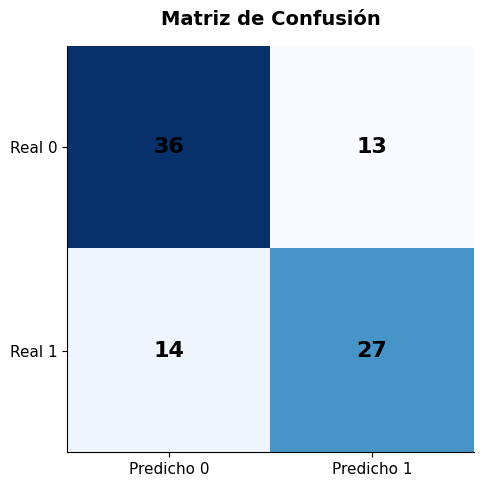

OBSERVACIONES:
   • TP: colaboradores que sí requieren capacitación y el modelo los detectó
   • FN: colaboradores que requieren capacitación pero el modelo NO los detectó
   • FP: el modelo dijo que requieren capacitación, pero en realidad no


In [17]:
# GRÁFICO: Matriz de confusión

cm = confusion_matrix(y_test, y_pred)

print("MATRIZ DE CONFUSIÓN:")
print("=" * 50)
print(f"                    Predicho negativo   Predicho positivo")
print(f"   Real negativo         TN = {cm[0, 0]:<12}   FP = {cm[0, 1]}")
print(f"   Real positivo         FN = {cm[1, 0]:<12}   TP = {cm[1, 1]}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=16, fontweight='bold')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Predicho 0', 'Predicho 1'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Real 0', 'Real 1'])
ax.set_title('Matriz de Confusión', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

print("OBSERVACIONES:")
print("   • TP: colaboradores que sí requieren capacitación y el modelo los detectó")
print("   • FN: colaboradores que requieren capacitación pero el modelo NO los detectó")
print("   • FP: el modelo dijo que requieren capacitación, pero en realidad no")

In [18]:
print("NOTA: las métricas provienen de datos SINTÉTICOS generados con las mismas variables predictoras;")
print("      sirven para demostrar la metodología, no para tomar decisiones sobre personas reales.\n")
# 5.6 INTERPRETACIÓN PRELIMINAR Y LIMITACIONES
top3 = coeficientes["variable"].head(3).tolist()

print("INTERPRETACIÓN:")
print("=" * 60)
print(f"El modelo de Regresión Logística alcanza un F1-Score de {f1:.2f} y un ROC-AUC de {roc_auc:.2f},")
print(f"lo que indica que distingue de forma aceptable a los colaboradores que requieren capacitación")
print(f"(el baseline tiene F1-Score de {f1_base:.2f}). Las variables más influyentes son {', '.join(top3)},")
print(f"lo que sugiere que RRHH debe priorizar a quienes tienen bajo desempeño y baja satisfacción.")
print(f"Sin embargo, deben considerarse las siguientes limitaciones:")

print("\nLIMITACIONES DEL MODELO:")
print("1. Tamaño de la muestra: el dataset real solo tiene 10 colaboradores; se usaron 600 datos sintéticos.")
print("2. Variables omitidas: no se incluyen factores como liderazgo del jefe o carga de trabajo real.")
print("3. Supuestos del modelo: la regresión logística supone relaciones lineales entre variables y probabilidad.")
print("4. Capacidad de generalización: debe validarse con datos reales antes de usarse para tomar decisiones.")
print("5. Circularidad: la etiqueta se generó con una fórmula de las mismas variables predictoras; el AUC está acotado por esa fórmula y no es evidencia de poder predictivo real.")


NOTA: las métricas provienen de datos SINTÉTICOS generados con las mismas variables predictoras;
      sirven para demostrar la metodología, no para tomar decisiones sobre personas reales.

INTERPRETACIÓN:
El modelo de Regresión Logística alcanza un F1-Score de 0.67 y un ROC-AUC de 0.75,
lo que indica que distingue de forma aceptable a los colaboradores que requieren capacitación
(el baseline tiene F1-Score de 0.00). Las variables más influyentes son desempeño, satisfaccion, horas_capacitacion,
lo que sugiere que RRHH debe priorizar a quienes tienen bajo desempeño y baja satisfacción.
Sin embargo, deben considerarse las siguientes limitaciones:

LIMITACIONES DEL MODELO:
1. Tamaño de la muestra: el dataset real solo tiene 10 colaboradores; se usaron 600 datos sintéticos.
2. Variables omitidas: no se incluyen factores como liderazgo del jefe o carga de trabajo real.
3. Supuestos del modelo: la regresión logística supone relaciones lineales entre variables y probabilidad.
4. Capacidad de 

In [19]:
# GUARDAR RESULTADOS
from pathlib import Path

BASE = Path('/content/')
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)

# Guardar predicciones
ruta_pred = BASE / 'datos' / 'procesados' / 'predicciones_hrtech_people_analytics.csv'
resultados.to_csv(ruta_pred, index=False, encoding='utf-8')
print(f"Predicciones guardadas: {ruta_pred.name}")

# Guardar métricas
ruta_metricas = BASE / 'documentos' / 'metricas_hrtech_people_analytics.csv'
comparacion.to_csv(ruta_metricas, index=False, encoding='utf-8')
print(f"Métricas guardadas: {ruta_metricas.name}")

# Guardar coeficientes
ruta_coef = BASE / 'documentos' / 'coeficientes_hrtech_people_analytics.csv'
coeficientes.to_csv(ruta_coef, index=False, encoding='utf-8')
print(f"Coeficientes guardados: {ruta_coef.name}")

# Descargar
from google.colab import files
files.download(str(ruta_pred))
files.download(str(ruta_metricas))
files.download(str(ruta_coef))
print("\nArchivos descargados")

Predicciones guardadas: predicciones_hrtech_people_analytics.csv
Métricas guardadas: metricas_hrtech_people_analytics.csv
Coeficientes guardados: coeficientes_hrtech_people_analytics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Archivos descargados
